In [26]:
import pandas as pd

# Load the Excel file
file_path = '0830.xlsx'
data_df = pd.read_excel(file_path,)  # 첫 번째 행을 건너뛰고 읽기

In [27]:
# 첫 번째 제공된 표에 기반한 매핑을 설정합니다.
type_mapping = {
    'A7B3': 'DP', 'AQ9F': 'Threshold', 'AX2N': 'Random',
    'BH5Z': 'DP', 'BA8J': 'Threshold', 'BP1Y': 'Random',
    'CT4C': 'DP', 'CM6D': 'Threshold', 'CL9K': 'Random',
    'DE2R': 'DP', 'DV7Q': 'Threshold', 'DE4K': 'Random',
    'ER8G': 'DP', 'EF3L': 'Threshold', 'EJ1N': 'Random',
    'FA1N': 'DP', 'FZ3K': 'Threshold', 'FB7R': 'Random',
}


In [28]:

# 성별, 이름, 소요시간 열 이름 정의
gender_column = 'Q6'
name_column = 'Q1'
time_column = 'Duration (in seconds)'  # 소요 시간 열

# Extract the relevant parts of the column names and map them to the appropriate type (DP, Threshold, Random)
def clean_column_name(name):
    for key in type_mapping.keys():
        if key in name:
            return f"{key}_{name.split('_')[-1]}"  # 예를 들어 A7B3_1, A7B3_2 등을 만듭니다.
    return name

# Apply the cleaning function to all column names
data_df.columns = data_df.columns.map(clean_column_name)

# JSON 변환 함수 정의
def convert_to_json(row):
    question_data = {}
    
    for question_id, question_type in type_mapping.items():
        if question_id[0] not in question_data:
            question_data[question_id[0]] = {
                "Q1": {},
                "Q2": {},
                "Q3": {}
            }
        
        question_data[question_id[0]]["Q1"][question_type] = int(row.get(f'{question_id}_1', 0))
        question_data[question_id[0]]["Q2"][question_type] = int(row.get(f'{question_id}_2', 0))
        question_data[question_id[0]]["Q3"][question_type] = int(row.get(f'{question_id}_3', 0))
    
    return {
        "name": row.get(name_column, "Unknown"),
        "time": int(row.get(time_column, 0)) // 60,  # 소요시간을 분으로 변환
        "gender": row.get(gender_column, "Unknown"),
        "question": question_data
    }

# 모든 사람의 데이터를 JSON으로 변환
json_data_list = []
for _, row in data_df.iloc[1:].iterrows():  # 첫 번째 행은 열 이름이므로 두 번째 행부터 시작
    json_data_list.append(convert_to_json(row))




In [29]:
data_df.iloc[1:]

,StartDate,EndDate,Status,IPAddress,Progress,Duration (in seconds),Finished,RecordedDate,ResponseId,RecipientLastName,...,DE4K_3,EJ1N_1,EJ1N_2,EJ1N_3,ER8G_1,ER8G_2,ER8G_3,EF3L_1,EF3L_2,EF3L_3
1,2024-08-07 15:21:00,2024-08-07 15:41:27,IP Address,143.248.199.5,100,1227,True,2024-08-07 15:41:28.891000,R_3qlaRcjlZE6AWhF,NaN,...,4,5,5,5,6,5,6,5,5,5
2,2024-08-07 15:34:34,2024-08-07 16:47:09,IP Address,143.248.6.43,100,4355,True,2024-08-07 16:47:10.711000,R_6ho1wYIAHVFL9Yd,NaN,...,2,3,4,3,5,5,6,4,3,3
3,2024-08-07 16:26:40,2024-08-07 16:49:01,IP Address,143.248.2.218,100,1340,True,2024-08-07 16:49:02.278000,R_4chgbxrbCcypYIP,NaN,...,1,6,2,2,6,6,6,2,1,2
4,2024-08-08 12:31:44,2024-08-08 14:50:58,IP Address,143.248.247.177,100,8353,True,2024-08-08 14:50:59.280000,R_81A7SERcSq4eLkM,NaN,...,1,4,1,1,5,5,5,4,3,3
5,2024-08-08 19:57:52,2024-08-08 21:26:54,IP Address,143.248.249.47,100,5342,True,2024-08-08 21:26:55.310000,R_6OFqvScgAzXnhUB,NaN,...,3,2,2,3,4,6,5,4,5,4
6,2024-08-09 09:59:35,2024-08-09 10:21:53,IP Address,143.248.102.46,100,1338,True,2024-08-09 10:21:54.740000,R_7wbrJmRPwXYaNWy,NaN,...,2,5,2,2,7,7,7,4,3,3
7,2024-08-09 10:01:01,2024-08-09 10:48:00,IP Address,223.39.194.208,100,2818,True,2024-08-09 10:48:01.240000,R_4wnqJnT7A4R1Nop,NaN,...,4,7,5,4,6,7,6,5,5,4
8,2024-08-09 12:52:00,2024-08-09 13:14:03,IP Address,143.248.8.85,100,1322,True,2024-08-09 13:14:04.594000,R_2Eh6bi04h3ZAPHD,NaN,...,3,5,6,5,6,7,6,5,5,4
9,2024-08-07 16:03:51,2024-08-09 15:28:04,IP Address,192.249.31.27,100,170652,True,2024-08-09 15:28:05.066000,R_2cJQY3PssWHU9bj,NaN,...,2,3,4,3,4,7,5,5,7,6


In [30]:
import json
output_file_path = 'output_json_data_list.json'

with open(output_file_path, 'w', encoding='utf-8') as f:
    json.dump(json_data_list, f, ensure_ascii=False, indent=4)

In [31]:
import json
import matplotlib.pyplot as plt
import numpy as np

# JSON 파일 불러오기

with open(output_file_path, 'r', encoding='utf-8') as f:
    json_data_list = json.load(f)


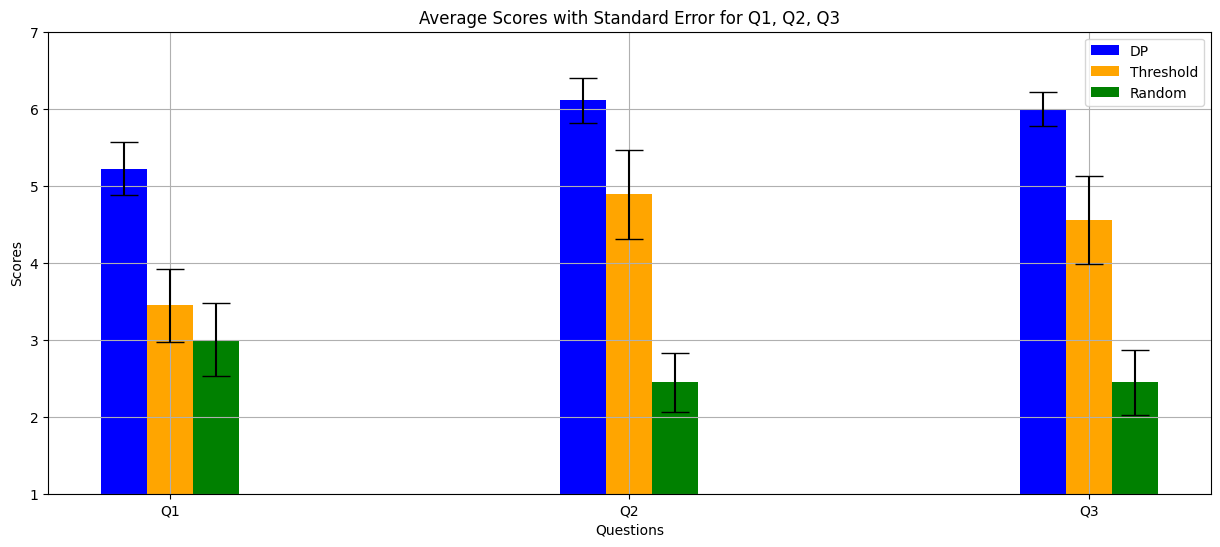

In [32]:

# 질문별 데이터를 추출
def extract_question_data(json_data_list, question_number):
    dp_values = []
    threshold_values = []
    random_values = []

    for data in json_data_list:
        question_data = data['question']['A'][f"Q{question_number}"]
        dp_values.append(question_data['DP'])
        threshold_values.append(question_data['Threshold'])
        random_values.append(question_data['Random'])
    
    return dp_values, threshold_values, random_values

# 데이터를 추출하고 세 질문의 데이터를 한 그래프에 표현하는 코드
# 데이터를 추출하고 세 질문의 데이터를 한 그래프에 표현하는 코드 (표준 오차 사용)
def plot_combined_question_data():
    dp_means, threshold_means, random_means = [], [], []
    dp_sems, threshold_sems, random_sems = [], [], []  # 표준 오차 계산을 위한 리스트

    for i in range(1, 4):
        dp_values, threshold_values, random_values = extract_question_data(json_data_list, i)
        
        dp_means.append(np.mean(dp_values))
        threshold_means.append(np.mean(threshold_values))
        random_means.append(np.mean(random_values))
        
        dp_sems.append(np.std(dp_values) / np.sqrt(len(dp_values)))
        threshold_sems.append(np.std(threshold_values) / np.sqrt(len(threshold_values)))
        random_sems.append(np.std(random_values) / np.sqrt(len(random_values)))

    # 그래프 생성
    labels = ['Q1', 'Q2', 'Q3']
    x = np.arange(len(labels))  # the label locations
    width = 0.1  # the width of the bars

    fig, ax = plt.subplots(figsize=(15, 6))
    
    # 각각의 막대 그래프
    ax.bar(x - width, dp_means, width, label='DP', yerr=dp_sems, capsize=10, color='blue')
    ax.bar(x, threshold_means, width, label='Threshold', yerr=threshold_sems, capsize=10, color='orange')
    ax.bar(x + width, random_means, width, label='Random', yerr=random_sems, capsize=10, color='green')

    # 그래프 설정
    ax.set_xlabel('Questions')
    ax.set_ylabel('Scores')
    ax.set_ylim(1, 7)
    ax.grid(True)
    ax.set_title('Average Scores with Standard Error for Q1, Q2, Q3')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()

    plt.show()

# 그래프 그리기
plot_combined_question_data()


# 표준 오차

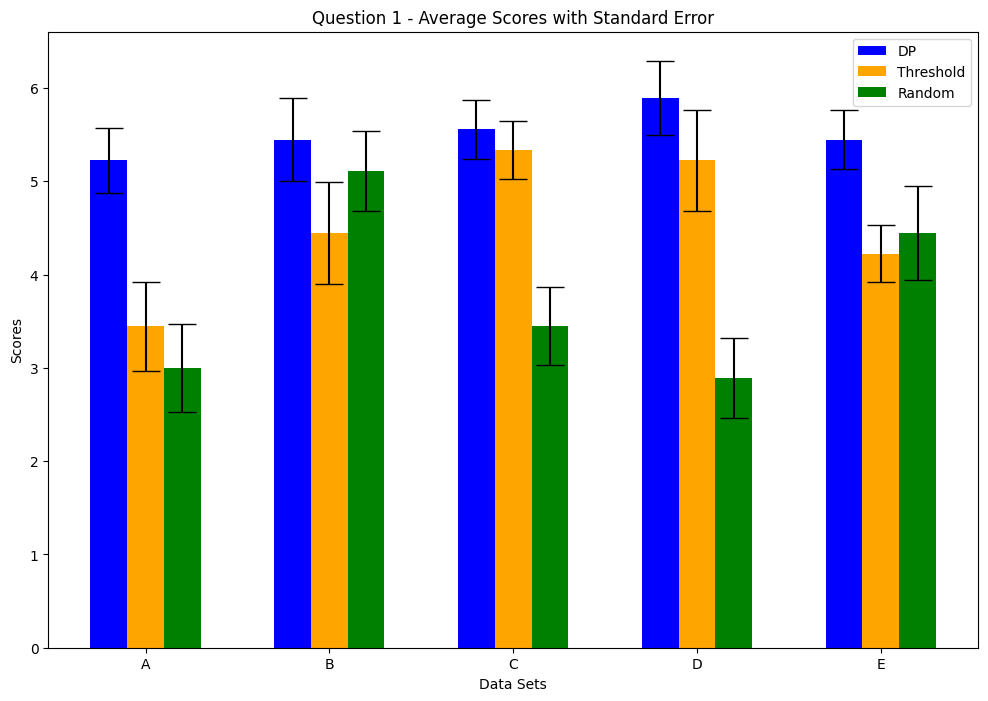

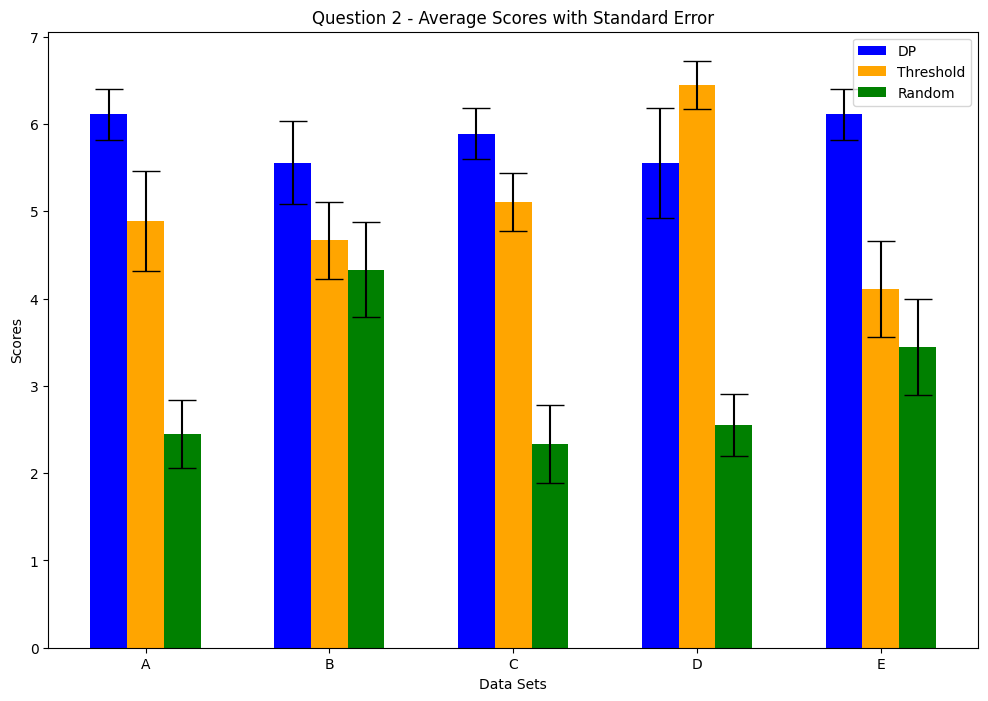

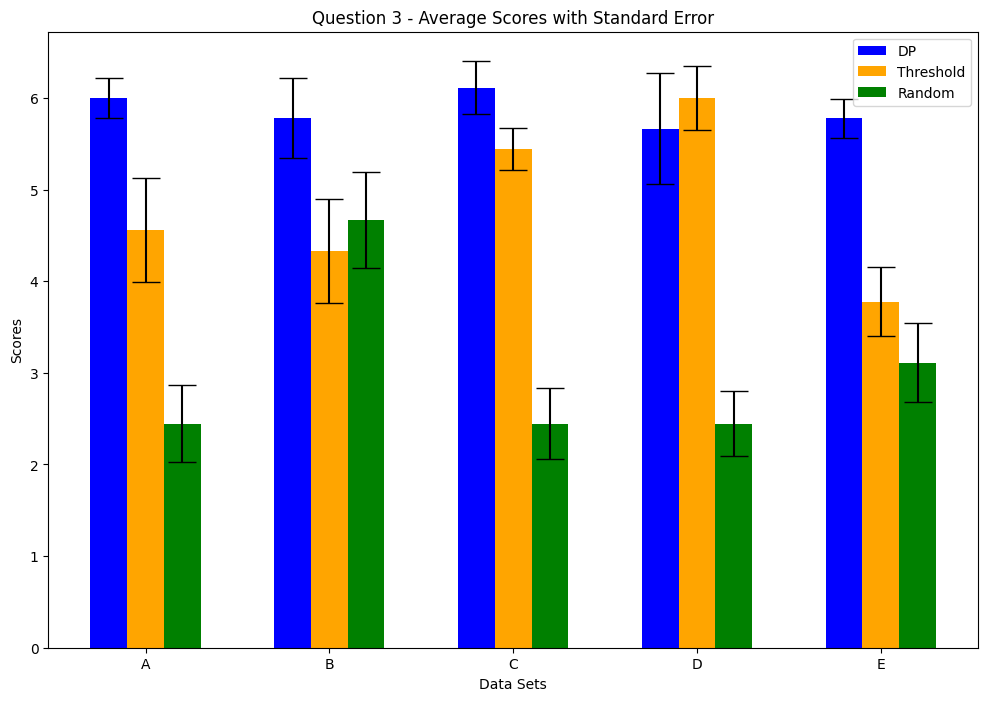

In [33]:
# 데이터를 추출하고 각각의 질문에 대해 A, B, C, D, E의 데이터를 표현하는 코드 (standard error 포함)
def extract_combined_question_data_with_error(json_data_list, question_number):
    data_points = {'A': [], 'B': [], 'C': [], 'D': [], 'E': []}
    
    for key in data_points.keys():
        dp_values = []
        threshold_values = []
        random_values = []
        
        for data in json_data_list:
            question_data = data['question'][key][f"Q{question_number}"]
            dp_values.append(question_data['DP'])
            threshold_values.append(question_data['Threshold'])
            random_values.append(question_data['Random'])
        
        data_points[key] = {
            'DP_mean': np.mean(dp_values), 'DP_std': np.std(dp_values), 'DP_se': np.std(dp_values) / np.sqrt(len(dp_values)),
            'Threshold_mean': np.mean(threshold_values), 'Threshold_std': np.std(threshold_values), 'Threshold_se': np.std(threshold_values) / np.sqrt(len(threshold_values)),
            'Random_mean': np.mean(random_values), 'Random_std': np.std(random_values), 'Random_se': np.std(random_values) / np.sqrt(len(random_values))
        }
    
    return data_points

def plot_combined_data_for_question_with_error(question_number):
    data_points = extract_combined_question_data_with_error(json_data_list, question_number)
    
    labels = ['A', 'B', 'C', 'D', 'E']
    x = np.arange(len(labels))  # the label locations
    width = 0.2  # the width of the bars

    fig, ax = plt.subplots(figsize=(12, 8))
    
    # 각각의 막대 그래프
    dp_means = [data_points[key]['DP_mean'] for key in labels]
    threshold_means = [data_points[key]['Threshold_mean'] for key in labels]
    random_means = [data_points[key]['Random_mean'] for key in labels]
    
    dp_ses = [data_points[key]['DP_se'] for key in labels]
    threshold_ses = [data_points[key]['Threshold_se'] for key in labels]
    random_ses = [data_points[key]['Random_se'] for key in labels]

    ax.bar(x - width, dp_means, width, label='DP', yerr=dp_ses, capsize=10, color='blue')
    ax.bar(x, threshold_means, width, label='Threshold', yerr=threshold_ses, capsize=10, color='orange')
    ax.bar(x + width, random_means, width, label='Random', yerr=random_ses, capsize=10, color='green')

    # 그래프 설정
    ax.set_xlabel('Data Sets')
    ax.set_ylabel('Scores')
    ax.set_title(f'Question {question_number} - Average Scores with Standard Error')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()

    plt.show()

# 질문 1, 2, 3에 대해 그래프 그리기 (표준 에러 포함)
for i in range(1, 4):
    plot_combined_data_for_question_with_error(i)

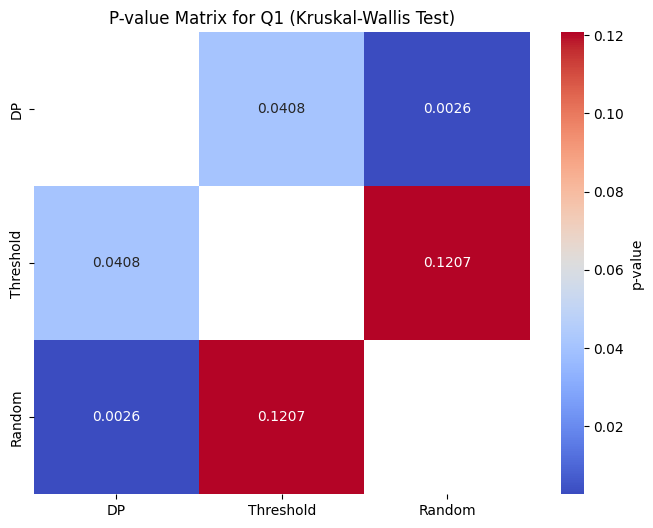

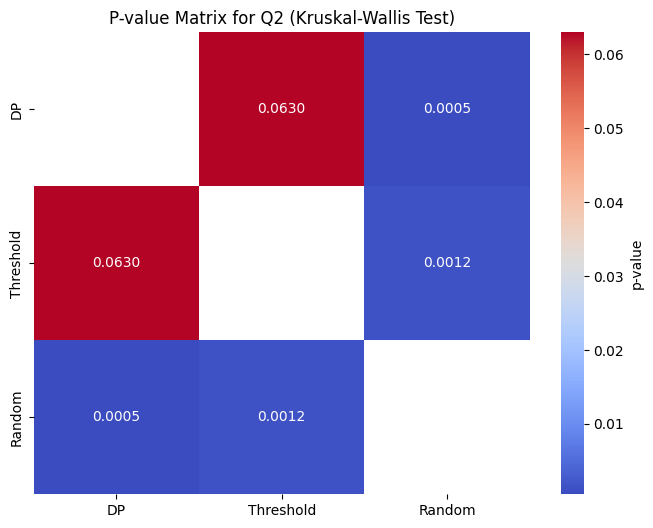

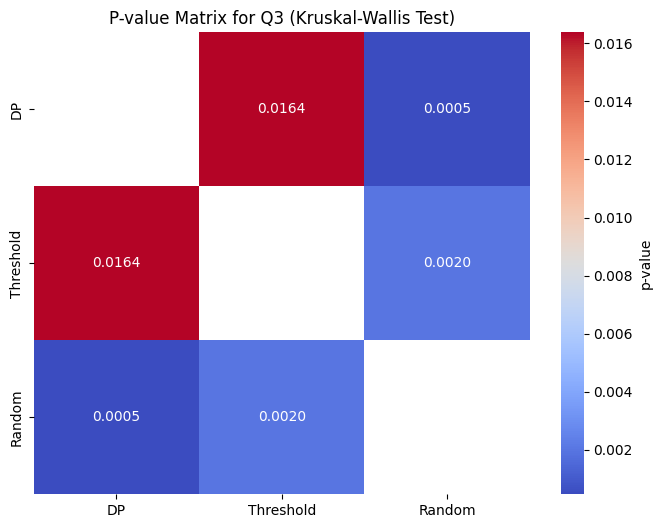

In [34]:

import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import kruskal


# 각 사람의 DP, Threshold, Random 평균을 계산하는 함수
def calculate_individual_averages(json_data_list, question_number):
    dp_averages = []
    threshold_averages = []
    random_averages = []
    
    for data in json_data_list:
        dp_values = []
        threshold_values = []
        random_values = []
        
        for key in ['A', 'B', 'C', 'D', 'E']:
            question_data = data['question'][key][f"Q{question_number}"]
            dp_values.append(question_data['DP'])
            threshold_values.append(question_data['Threshold'])
            random_values.append(question_data['Random'])
        
        dp_averages.append(np.mean(dp_values))
        threshold_averages.append(np.mean(threshold_values))
        random_averages.append(np.mean(random_values))
    
    return dp_averages, threshold_averages, random_averages

# p-value 계산 및 매트릭스 생성
def calculate_p_value_matrix(dp_averages, threshold_averages, random_averages):
    _, p_dp_threshold = kruskal(dp_averages, threshold_averages)
    _, p_threshold_random = kruskal(threshold_averages, random_averages)
    _, p_dp_random = kruskal(dp_averages, random_averages)
    
    p_value_matrix = np.array([
        [np.nan, p_dp_threshold, p_dp_random],
        [p_dp_threshold, np.nan, p_threshold_random],
        [p_dp_random, p_threshold_random, np.nan]
    ])
    
    return p_value_matrix

# 각 질문에 대해 p-value 매트릭스를 생성하는 함수
def generate_p_value_matrices_for_questions(json_data_list):
    p_value_matrices = {}
    for i in range(1, 4):  # 질문 1, 2, 3
        dp_averages, threshold_averages, random_averages = calculate_individual_averages(json_data_list, i)
        p_value_matrix = calculate_p_value_matrix(dp_averages, threshold_averages, random_averages)
        p_value_matrices[f'Q{i}'] = p_value_matrix
    
    return p_value_matrices

# 시각화 함수
def plot_p_value_matrix(matrix, question):
    labels = ['DP', 'Threshold', 'Random']
    plt.figure(figsize=(8, 6))
    sns.heatmap(matrix, annot=True, fmt=".4f", cmap='coolwarm', xticklabels=labels, yticklabels=labels, cbar_kws={'label': 'p-value'})
    plt.title(f'P-value Matrix for {question} (Kruskal-Wallis Test)')
    plt.show()

# p-value 매트릭스 생성 및 시각화
p_value_matrices = generate_p_value_matrices_for_questions(json_data_list)

# 시각화 출력
for question, matrix in p_value_matrices.items():
    plot_p_value_matrix(matrix, question)

In [35]:
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

def kruskal_wallis_with_posthoc(dp_averages, threshold_averages, random_averages):
    # Combine all data
    all_data = np.concatenate([dp_averages, threshold_averages, random_averages])
    groups = ['DP'] * len(dp_averages) + ['Threshold'] * len(threshold_averages) + ['Random'] * len(random_averages)
    
    # Perform Kruskal-Wallis H-test
    h_statistic, p_value = stats.kruskal(dp_averages, threshold_averages, random_averages)
    
    # Perform post-hoc Dunn's test
    if p_value < 0.05:
        posthoc = pairwise_tukeyhsd(all_data, groups)
        return h_statistic, p_value, posthoc
    else:
        return h_statistic, p_value, None

In [36]:
# 각 질문에 대해 Kruskal-Wallis 검정 및 post-hoc 분석 수행
for i in range(1, 4):
    dp_averages, threshold_averages, random_averages = calculate_individual_averages(json_data_list, i)
    h_statistic, p_value, posthoc = kruskal_wallis_with_posthoc(dp_averages, threshold_averages, random_averages)
    
    print(f"Question {i}:")
    print(f"H-statistic: {h_statistic}")
    print(f"p-value: {p_value}")
    
    if posthoc is not None:
        print("Post-hoc analysis results:")
        print(posthoc)
    print("\n")

Question 1:
H-statistic: 10.531926517790062
p-value: 0.005164415961990436
Post-hoc analysis results:
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1   group2  meandiff p-adj   lower   upper  reject
-------------------------------------------------------
    DP    Random  -1.7333 0.0021 -2.8554 -0.6112   True
    DP Threshold  -0.9778 0.0959 -2.0999  0.1443  False
Random Threshold   0.7556 0.2327 -0.3665  1.8776  False
-------------------------------------------------------


Question 2:
H-statistic: 17.123634507401725
p-value: 0.00019127138898119086
Post-hoc analysis results:
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1   group2  meandiff p-adj   lower  upper  reject
------------------------------------------------------
    DP    Random  -2.8222    0.0 -3.8904 -1.754   True
    DP Threshold     -0.8 0.1691 -1.8682 0.2682  False
Random Threshold   2.0222 0.0002   0.954 3.0904   True
------------------------------------------------------


Question 3:
H-s